# Concept

From bandstructure, extract the point of the path from "bandstructure"

In [1]:
epsilon=7E-1

In [2]:
import numpy as np
import matplotlib.pyplot as plt
folder="/home/thibault.derrien/Documents/octopus.data/09-Au/Au-1x1x1-k-16x16x16-Mesh0.377945225092-Mesh0.377945225092-T0e0-Te0.025eV-PBE-ME/"
path=folder+"bandstructure"
bands=np.loadtxt(path, dtype="float32")

In [3]:
bands

array([[0.        , 0.        , 0.        , ..., 0.98332626, 0.98337   ,
        0.98337   ],
       [0.00154096, 0.005     , 0.        , ..., 0.98317766, 0.983311  ,
        0.9833369 ],
       [0.00308192, 0.01      , 0.        , ..., 0.98266053, 0.9832088 ,
        0.9832373 ],
       ...,
       [0.99747384, 0.4975    , 0.0075    , ..., 0.6759355 , 0.6762732 ,
        0.9204416 ],
       [0.9987369 , 0.49875   , 0.00375   , ..., 0.67600363, 0.67610955,
        0.92031753],
       [1.        , 0.5       , 0.        , ..., 0.67602646, 0.676055  ,
        0.9202761 ]], dtype=float32)

In [4]:
kindex=bands[:,0]
kx=bands[:,1]
ky=bands[:,2]
kz=bands[:,3]
kx_xx=np.gradient(np.gradient(kx))
ky_yy=np.gradient(np.gradient(ky))
kz_zz=np.gradient(np.gradient(kz))

In [5]:
slope_x=np.gradient(kx)/np.gradient(kindex)
slope_y=np.gradient(ky)/np.gradient(kindex)
slope_z=np.gradient(kz)/np.gradient(kindex)
discont_x=np.fabs(np.gradient(slope_x)/np.gradient(kindex))
discont_y=np.fabs(np.gradient(slope_y)/np.gradient(kindex))
discont_z=np.fabs(np.gradient(slope_z)/np.gradient(kindex))


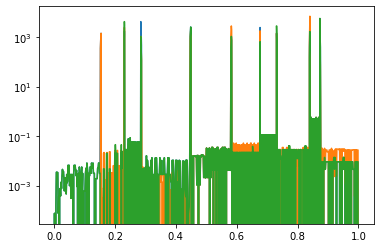

In [14]:
plt.figure()
plt.semilogy(kindex,discont_x, label="kx")
plt.semilogy(kindex,discont_y, label="ky")
plt.semilogy(kindex,discont_z, label="kz")
#plt.ylim([1e-1,1E0])
plt.show()

In [15]:
condition=np.logical_or(np.fabs(discont_x)>epsilon, np.fabs(discont_y)>epsilon)
condition2=np.logical_or(condition, np.fabs(discont_z)>epsilon)
print(np.shape(condition2))
print(np.shape(kindex))

(1001,)
(1001,)


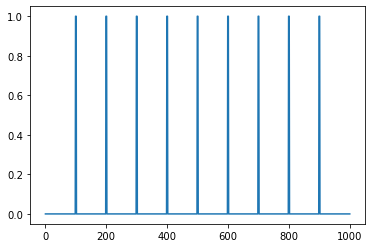

In [16]:
plt.figure()
plt.plot(condition2)
plt.show()

In [17]:
test2=kindex[(condition2)]
test3=np.select(condition2, kindex)

We need to find points where 

In [23]:
test2

array([0.15255512, 0.15409608, 0.15486656, 0.23037364, 0.23114412,
       0.23168893, 0.2850805 , 0.2856253 , 0.28725976, 0.44743446,
       0.4490689 , 0.4504034 , 0.5811855 , 0.58252   , 0.58346367,
       0.6759406 , 0.6768842 , 0.677429  , 0.7308206 , 0.7313654 ,
       0.732455  , 0.83923817, 0.8403278 , 0.8406614 , 0.87335694,
       0.87369055, 0.8749536 ], dtype=float32)

In [26]:
np.shape(test2)

(27,)

It seems 3 values are captured for each discontinuity. Let's average these 3 each time. 

In [32]:
kindex_dis=np.reshape(test2, [int(len(test2)/3), 3])
print(kindex_dis)

[[0.15255512 0.15409608 0.15486656]
 [0.23037364 0.23114412 0.23168893]
 [0.2850805  0.2856253  0.28725976]
 [0.44743446 0.4490689  0.4504034 ]
 [0.5811855  0.58252    0.58346367]
 [0.6759406  0.6768842  0.677429  ]
 [0.7308206  0.7313654  0.732455  ]
 [0.83923817 0.8403278  0.8406614 ]
 [0.87335694 0.87369055 0.8749536 ]]


In [37]:
np.mean(kindex_dis, axis=1)

array([0.15383925, 0.2310689 , 0.2859885 , 0.4489689 , 0.5823898 ,
       0.6767512 , 0.73154706, 0.8400758 , 0.8740004 ], dtype=float32)

IndexError: arrays used as indices must be of integer (or boolean) type